In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize

##### 1. Setup Data from handwritten **maths**

In [8]:
x = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([[5.0],
              [16.0]])

*   Setting initial parameters

In [9]:
m = np.array([[-1.0],
             [2.0]])
b = np.array([[1.0],
              [1.0]])
alpha = 0.01
num_iterations = 3
n = len(y)

*   History tracking for visualization

In [10]:
m_history = [m.copy()]
b_history = [b.copy()]
cost_history = []

print("=== Executing Manual Gradient Descent Loop ===")

=== Executing Manual Gradient Descent Loop ===


##### 2. Step-by-step Gradient Descent Loop

In [12]:
for i in range(1, num_iterations + 1):
    # Predictions (Ŷ = Xm + b)
    y_hat = np.dot(x, m) + b

    # Error Vector (e)
    error = y_hat - y

    # Cost Function J = (1/n) * e^T * e
    cost = (1.0 / n) * np.sum(error**2)
    cost_history.append(cost)

In [17]:
# Explicit Gradient computation
dj_dm = (2.0 / n) * np.dot(x.T, error)
dj_db = (2.0 / n) * np.sum(error)

print(f"\n--- Iteration {i} ---")
print(f"Predictions Ŷ:\n{y_hat}")
print(f"Error Vector e:\n{error}")
print(f"Cost J: {cost:.4f}")
print(f"Gradient wrt m:\n{dj_dm}")
print(f"Gradient wrt b:\n{dj_db}")


--- Iteration 3 ---
Predictions Ŷ:
[[ 6.]
 [17.]]
Error Vector e:
[[1.]
 [1.]]
Cost J: 1.0000
Gradient wrt m:
[[ 5.]
 [13.]]
Gradient wrt b:
2.0


In [18]:
### Parameter Updates ###
m -= alpha * dj_dm
b -= alpha * dj_db

m_history.append(m.copy())
b_history.append(b.copy())

### Calculate final cost post-loop
final_cost = (1.0 / n) * np.sum((np.dot(x, m) + b - y)**2)
cost_history.append(final_cost)

##### 3. Scipy Minimization Verification

In [19]:
def objective_function(params):
  m_opt = params[0:2].reshape(2,1)
  b_opt = params[2:4].reshape(2,1)
  y_pred = np.dot(x, m_opt) + b_opt
  return (1.0 / n) * np.sum((y_pred - y)**2)

initial_guess = np.array([-1.0, 2.0, 1.0, 1.0])
scipy_result = minimize(objective_function, initial_guess, method='BFGS')

print("\n" + "="*40)
print("=== Optimization Comparison ===")
print("="*40)
print(f"Manual GD  (3 Steps). -> m: {m.flatten()}, b: {b.flatten()}")
print(f"Scipy Optimal         -> m: {scipy_result.x[0:2]}, b: {scipy_result.x[2:4]}")


=== Optimization Comparison ===
Manual GD  (3 Steps). -> m: [-1.1   1.74], b: [0.96 0.96]
Scipy Optimal         -> m: [-0.93129739  1.85496169], b: [0.36641227 1.17557263]


##### 4. Matplotlib Visualization

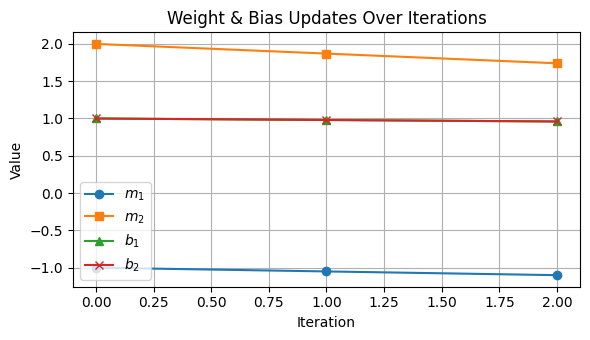

In [21]:
m_hist = np.array(m_history).squeeze()
b_hist = np.array(b_history).squeeze()

### Plot 1: Parameter updates over epochs
plt.figure(figsize=(6, 3.5))
plt.plot(m_hist[:,0], label='$m_1$', marker='o')
plt.plot(m_hist[:,1], label='$m_2$', marker='s')
plt.plot(b_hist[:,0], label='$b_1$', marker='^')
plt.plot(b_hist[:,1], label='$b_2$', marker='x')
plt.title('Weight & Bias Updates Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

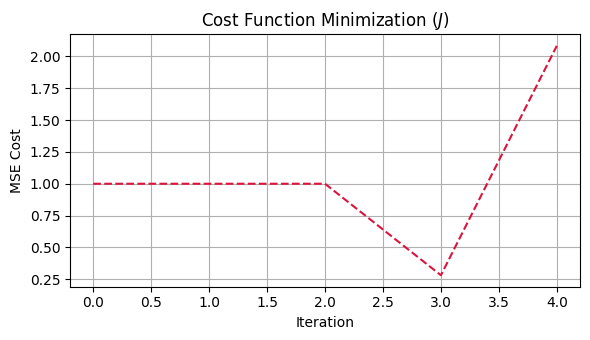

In [22]:
### Plot 2: Cost error trajectory
plt.figure(figsize=(6, 3.5))
plt.plot(cost_history, color='crimson', linestyle='--')
plt.title('Cost Function Minimization ($J$)')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.grid(True)
plt.tight_layout()
plt.show()